# Bank Marketing naudojant TensorFlow **Decision Forests**

Užduotis **1.3** kurso *Gilusis mokymas* (VILNIUS TECH): perdaryti *abu* dėstytojo Colab užrašus su kitais verslo duomenimis. Neuroninis tinklas yra [`BankMarketing_NN.ipynb`](BankMarketing_NN.ipynb); čia — antrasis užrašas.

**Originalas.** Algirdas Laukaitis, *AdventureWorks DW using TensorFlow Decision Forests* (`AdventureWorksDW_Decision Forests.ipynb`).  
Colab: [AdventureWorks DW using TensorFlow Decision Forests](https://colab.research.google.com/drive/1zE7b6UlSOreWsgD7lGQOVfEki_xTRDAX).

**Ši versija** kartoja tuos pačius langelius (1.1–5): CSV → valymas → 90:10 padalijimas (be validacijos) → `tfdf.keras.pd_dataframe_to_tf_dataset` → `RandomForestModel(num_trees=10, max_depth=15)` → mokymas, tikslumas + AUC, mokymo kreivės, vieno medžio piešinys → išsaugojimas ir prognozė. Tie patys UCI Bank Marketing duomenys, `duration` išmestas. `dtreeviz` langeliai praleisti — originale jie irgi užkomentuoti / priklauso nuo Colab.


*Algirdas Laukaitis (originalas) → Bank Marketing replika*

## <font color='Dark Maroon'>Bank Marketing using TensorFlow <b>Decision Forests</b></font>

Originalo schema: [AdventureWorks DW schema](https://github.com/aalgirdas/AdventureWorksDW/blob/main/AdventureWorksDW2008.png)

Duomenys: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro et al., 2014). Klasė `y` = ar klientas užsisakė terminuotą indėlį.


<br><br>

---
# <font color='Dark Maroon'>Step 1. From a csv data file that is available online to 2 DataFrame tables:  training and test</font>

Originalas dalija tik į **mokymo ir testavimo** aibes (90:10). Atsitiktiniams miškams validacijos aibė nebūtina: kiekvienas medis mokomas iš bootstrap imties, o klaida skaičiuojama iš *out-of-bag* eilučių.


## 1.1 Įkeliame `bank-additional-full.csv` į DataFrame

Originalas skaitė `vTargetMail.csv` su `sep='\t'`. Čia — tas pats UCI Bank Marketing CSV kaip NN užrašuose (`sep=';'`). Pirmiausia vietinė kopija `data/`, kitaip UCI zip be Kaggle prisijungimo.


In [1]:
from pathlib import Path
import io
import zipfile
import urllib.request

import pandas as pd

UCI_ZIP_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
LOCAL_CANDIDATES = [
    Path("data/bank-additional-full.csv"),
    Path("1.3/data/bank-additional-full.csv"),
]


def load_bank_marketing():
    for path in LOCAL_CANDIDATES:
        if path.is_file():
            print(f"Skaitome vietinį failą: {path.resolve()}")
            return pd.read_csv(path, sep=";")

    print(f"Vietinio failo nėra — atsisiunčiame UCI zip: {UCI_ZIP_URL}")
    with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as resp:
        raw = io.BytesIO(resp.read())
    with zipfile.ZipFile(raw) as zf:
        with zf.open("bank-additional/bank-additional-full.csv") as handle:
            return pd.read_csv(handle, sep=";")


df = load_bank_marketing()
print("The dataframe has {} rows and {} columns.".format(df.shape[0], df.shape[1]))


Skaitome vietinį failą: /workspace/1.3/data/bank-additional-full.csv
The dataframe has 41188 rows and 21 columns.


## 1.2 Peržiūrime pirmas eilutes, kad suprastume, kurie požymiai tinka uždaviniui

Originalas rodė `df[0:5]`. Žiūrime stulpelių tipus ir žymę `y`.


In [2]:
# print(df.iloc[5])
df[0:5]


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1.3 Pašaliname nereikalingus požymius ir pervadiname žymę į `target`

> *And we rename some attributes because we want to reuse the code snippets from official TensorFlow tutorials. Renaming an attribute is much easier than rewriting code.*

Originalas išmetė identifikatorius ir `BikeBuyer` pervadino į `target`. Čia `y` → `target` (0/1).

**Kodėl išmetame `duration`?** Tai paskutinio skambučio trukmė sekundėmis — žinoma tik *po* pokalbio, kartu su `y`. Ilgas pokalbis stipriai susijęs su `yes`, todėl tai tikslinės žymės nutekėjimas (*target leakage*). Prieš skambinant trukmė dar nežinoma.


In [3]:
# duration nutekina žymę y — žr. paaiškinimą markdown langelyje
df = df.copy()
df.drop(columns=["duration"], inplace=True)
df.rename(
    columns={
        "y": "target",
        "emp.var.rate": "emp_var_rate",
        "cons.price.idx": "cons_price_idx",
        "cons.conf.idx": "cons_conf_idx",
        "nr.employed": "nr_employed",
    },
    inplace=True,
)
df["target"] = (df["target"] == "yes").astype("int64")

print(df.iloc[0])
print("---------------")
print("Klasės (0 = ne, 1 = taip):")
print(df["target"].value_counts(normalize=True).round(4))


age                        56
job                 housemaid
marital               married
education            basic.4y
default                    no
housing                    no
loan                       no
contact             telephone
month                     may
day_of_week               mon
campaign                    1
pdays                     999
previous                    0
poutcome          nonexistent
emp_var_rate              1.1
cons_price_idx         93.994
cons_conf_idx           -36.4
euribor3m               4.857
nr_employed            5191.0
target                      0
Name: 0, dtype: object
---------------
Klasės (0 = ne, 1 = taip):
target
0    0.8873
1    0.1127
Name: proportion, dtype: float64


## 1.4 Padalijame DataFrame į mokymo ir testavimo aibes

Kai mokome modelį, turime patikrinti jį su nematytais duomenimis. Originalas rašo apie tris aibes, bet pažymi: *(But for Decision Forests we don't need validation set)*. Atsitiktinis miškas kiekvieną medį mokina iš bootstrap imties, o OOB eilutės jau atlieka validacijos vaidmenį.

Santykis kaip originale: **90 : 10**. `np.split(df.sample(frac=1), ...)` dabartiniame pandas grąžina `ndarray`, todėl dalijame su `iloc`. `random_state=42` — tas pats maišymas kaip NN užrašuose, todėl **testo 10 % sutampa** su NN testu (NN validacija buvo iš mokymo 90 %).


In [4]:
import numpy as np

SEED = 42
np.random.seed(SEED)

# The dataset is in a single pandas DataFrame. Split it into training, and test sets using a, for example, 90:10 ratio, respectively.
# Originalas: train, test = np.split(df.sample(frac=1), [int(0.9*len(df))])
df_shuffled = df.sample(frac=1, random_state=SEED)
n = len(df_shuffled)
train = df_shuffled.iloc[: int(0.9 * n)].copy()
test = df_shuffled.iloc[int(0.9 * n) :].copy()
print(len(train), "training examples")
print(len(test), "test examples")
print("Teigiama klasė teste:", f"{int(test['target'].sum())}/{len(test)} = {test['target'].mean():.1%}")


37069 training examples
4119 test examples
Teigiama klasė teste: 484/4119 = 11.8%


<br><br>

---


# <font color='Dark Maroon'>Step 2. From DataFrame table to TensorFlow dataset data</font>


## Import TensorFlow and other libraries

`tensorflow_decision_forests` (TF-DF) apjungia Yggdrasil Decision Forests su Keras. `pd_dataframe_to_tf_dataset` pats atpažįsta skaitinius ir kategorinius stulpelius — nereikia `StringLookup` / `Normalization`, kaip NN užrašuose.

**Versijos.** Šioje VM: TensorFlow 2.19.0 + TF-DF 1.12.0. TF 2.19 deklaruoja `protobuf<6`, o TF-DF 1.12 / `ydf` 0.16 sugeneruotas su Protobuf 6.31.1, todėl jei importas krenta su `VersionError`, įdiegiame `protobuf==6.31.1`.


In [5]:
import subprocess
import sys

# Originalas: !pip install tensorflow_decision_forests


def _install(*pkgs: str) -> None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *pkgs],
        stdout=subprocess.DEVNULL,
    )


try:
    import tensorflow_decision_forests as tfdf
except Exception:
    _install("tensorflow_decision_forests")
    try:
        import tensorflow_decision_forests as tfdf
    except Exception as exc:
        msg = f"{type(exc).__name__}: {exc}"
        if "protobuf" in msg.lower() or "Protobuf" in msg:
            print("TF-DF protobuf nesuderinamumas — pin'iname protobuf==6.31.1")
            _install("protobuf==6.31.1")
            import importlib

            import google.protobuf

            importlib.reload(google.protobuf)
            import tensorflow_decision_forests as tfdf
        else:
            raise

print("tfdf", tfdf.__version__)


2026-10-21 05:57:39.641388: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792562259.656350    5795 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792562259.660476    5795 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792562259.674263    5795 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792562259.674281    5795 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792562259.674283    5795 computation_placer.cc:177] computation placer alr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

tfdf 1.12.0


In [6]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")

import tensorflow_decision_forests as tfdf

train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train, label="target")
test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(test, label="target")


2026-10-21 05:57:41.635054: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


<br><br>

---


# <font color='Dark Maroon'>Step 3. Model</font>

`RandomForestModel` — ansamblis iš `num_trees` CART medžių. Kiekvienas medis mato atsitiktinę eilučių ir požymių imtį; galutinė prognozė — balsų / tikimybių vidurkis. `max_depth=15` riboja medžio gylį (kaip originale, `num_trees=10` — mažas miškas, kad mokymas būtų greitas ir medį būtų galima nupiešti).


In [7]:
model_1 = tfdf.keras.RandomForestModel(num_trees=10, max_depth=15)  # num_trees=100 , max_depth=15 , verbose=0


Use /tmp/tmpygv6fta4 as temporary training directory


<br><br>

---


# <font color='Dark Maroon'>Step 4. Train and evaluate the model</font>


<br>

## <font color='Dark Maroon'>Train 🏃‍♂️</font>

`fit` čia nėra gradientinis nusileidimas: Yggdrasil iš karto pastato visus medžius. Epochų nėra — vienas kvietimas.


In [8]:
model_1.fit(train_ds)


Reading training dataset...


Training dataset read in 0:00:01.898203. Found 37069 examples.


Training model...


Model trained in 0:00:00.199954


Compiling model...


I0000 00:00:1792562263.651485    5795 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1792562263.651567    5795 kernel.cc:783] Collect training examples
I0000 00:00:1792562263.651578    5795 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1792562263.651929    5795 kernel.cc:401] Number of batches: 38
I0000 00:00:1792562263.651939    5795 kernel.cc:402] Number of examples: 37069
I0000 00:00:1792562263.660722    5795 data_spec_inference.cc:354] 1 item(s) have been pruned (i.e. they are considered out of dictionary) for the column default (2 item(s) left) because min_value_count=5 and max_number_of_unique_values=2000
I0000 00:00:17925

Model compiled.


<br>


## <font color='Dark Maroon'>Evaluate ⚖️</font>

Originalas matavo tik `accuracy`. Bank Marketing klasės nesubalansuotos (~11 % `yes`), todėl šalia tikslumo skaičiuojame **AUC**.


In [9]:
from sklearn.metrics import accuracy_score, roc_auc_score

model_1.compile(metrics=["accuracy"])
evaluation = model_1.evaluate(test_ds, return_dict=True)
print(f'{evaluation["accuracy"]:.4f}')
print("Keras evaluate:", evaluation)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model_1.predict(test_ds, verbose=0).ravel()
y_hat = (y_prob >= 0.5).astype(int)
test_accuracy = float(accuracy_score(y_true, y_hat))
test_auc = float(roc_auc_score(y_true, y_prob))
print("Test accuracy (slenkstis 0.5):", round(test_accuracy, 4))
print("Test AUC:", round(test_auc, 4))


1/5 [=====>........................] - ETA: 1s - loss: 0.0000e+00 - accuracy: 0.8990

5/5 [==============================] - 0s 4ms/step - loss: 0.0000e+00 - accuracy: 0.8956


0.8956
Keras evaluate: {'loss': 0.0, 'accuracy': 0.895605742931366}
Test accuracy (slenkstis 0.5): 0.8932
Test AUC: 0.759


<br>


## <font color='Dark Maroon'>Plotting the training logs 🧾</font>

`make_inspector().training_logs()` grąžina *out-of-bag* tikslumą ir logloss po kiekvieno pridėto medžio. Jei kreivė dar kyla ties 10 medžiu, didesnis `num_trees` dar padėtų.


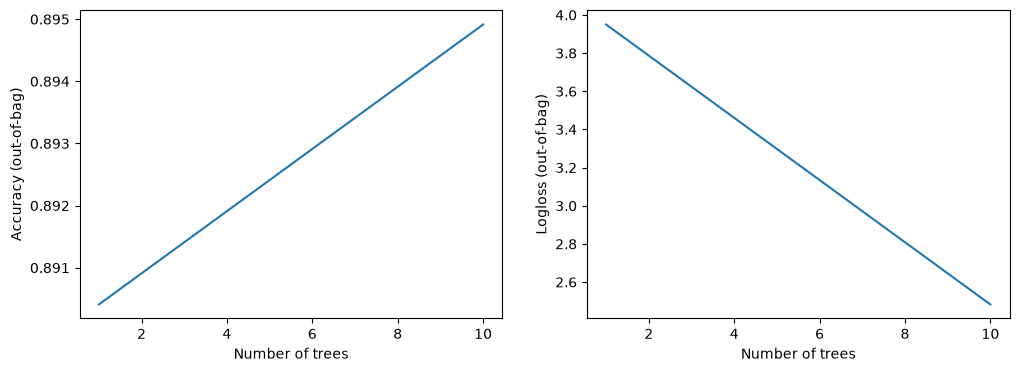

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt

logs = model_1.make_inspector().training_logs()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot([log.num_trees for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Accuracy (out-of-bag)")

plt.subplot(1, 2, 2)
plt.plot([log.num_trees for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Logloss (out-of-bag)")

plt.show()


<br>




## <font color='Dark Maroon'>Let's choose one tree 🌲 from the forest (tree_idx=...) and plot the model</font>

`plot_model_in_colab` piešia pasirinktą medį (`tree_idx=0`). Šakose matyti požymis ir slenkstis, lapuose — klasės pasiskirstymas. Jei Colab pagalbinė funkcija neveikia, rodome tą patį HTML per `plot_model`.


In [11]:
from IPython.display import display

# Originalas grąžina HTML objektą (Colab jį parodo kaip paskutinę langelio reikšmę).
# Čia kviečiame display, kad medis matytųsi ir Jupyter / nbclient aplinkoje.
display(tfdf.model_plotter.plot_model_in_colab(model_1, tree_idx=0, max_depth=15))  ## The decision tree number is defined by the tree_idx=... parameter


<br><br>

---


# <font color='Dark Maroon'> Step 5. Perform inference 🛠</font>


## <font color='Dark Maroon'> Save 💾 </font>


In [12]:
# model_1.save("BankMarketing_RandomForest_trees10.keras")
model_1.save("BankMarketing_RandomForest_trees10")


INFO:tensorflow:Assets written to: BankMarketing_RandomForest_trees10/assets


INFO:tensorflow:Assets written to: BankMarketing_RandomForest_trees10/assets


## <font color='Dark Maroon'> Load ⚙️</font>

Keras 3 TF-DF SavedModel dažnai įkeliamas kaip `TFSMLayer` (kaip originale), nes tai ne standartinis `.keras` objektas.


In [13]:
import tensorflow as tf

# reloaded_model = tf.keras.models.load_model("BankMarketing_RandomForest_trees10")
reloaded_model = tf.keras.layers.TFSMLayer(
    "BankMarketing_RandomForest_trees10", call_endpoint="serving_default"
)
print(type(reloaded_model))


I0000 00:00:1792562265.692921    5825 decision_forest.cc:808] Model loaded with 10 root(s), 19372 node(s), and 19 input feature(s).


<class 'keras.src.export.tfsm_layer.TFSMLayer'>


## <font color='Dark Maroon'> New data  🗃️</font>


In [14]:
sample = {
    "age": 35,
    "job": "admin.",
    "marital": "married",
    "education": "university.degree",
    "default": "no",
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "month": "aug",
    "day_of_week": "thu",
    "campaign": 1,
    "pdays": 999,
    "previous": 0,
    "poutcome": "nonexistent",
    "emp_var_rate": 1.4,
    "cons_price_idx": 93.444,
    "cons_conf_idx": -36.1,
    "euribor3m": 4.963,
    "nr_employed": 5228.1,
}


In [15]:
sample


{'age': 35,
 'job': 'admin.',
 'marital': 'married',
 'education': 'university.degree',
 'default': 'no',
 'housing': 'yes',
 'loan': 'no',
 'contact': 'cellular',
 'month': 'aug',
 'day_of_week': 'thu',
 'campaign': 1,
 'pdays': 999,
 'previous': 0,
 'poutcome': 'nonexistent',
 'emp_var_rate': 1.4,
 'cons_price_idx': 93.444,
 'cons_conf_idx': -36.1,
 'euribor3m': 4.963,
 'nr_employed': 5228.1}

## <font color='Dark Maroon'> Predict  🔮</font>

Originalas prognozuoja su `model_1.predict` (ne per `reloaded_model`). TF-DF binarinei klasei grąžina teigiamos klasės tikimybę.


In [16]:
new_observation_df = pd.DataFrame([sample])
new_observation_ds = tfdf.keras.pd_dataframe_to_tf_dataset(new_observation_df)
predictions = model_1.predict(new_observation_ds)
print(predictions)
print(
    "The likelihood of SUBSCRIBING TO A TERM DEPOSIT for this specific CLIENT is %.1f percent.  "
    % (100 * float(predictions.ravel()[0]))
)


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 34ms/step


[[0.]]
The likelihood of SUBSCRIBING TO A TERM DEPOSIT for this specific CLIENT is 0.0 percent.  


In [17]:
# predictions = reloaded_model.predict(test_ds)
print("Perkeltas sluoksnis paruoštas:", reloaded_model is not None)


Perkeltas sluoksnis paruoštas: True
